# Visualização Inicial dos Dados Brutos

Este notebook tem o objetivo de realizar uma plotagem simples e direta dos dados brutos extraídos no passo anterior. O foco aqui é apenas conferir a localização dos pontos em um mapa base para garantirmos que os dados estão na região correta (Rio Bacanga).

Neste primeiro momento, todos os pontos serão pretos, sem mapa de cores relacionado à profundidade.

In [3]:
import sqlite3
import pandas as pd
import folium
import numpy as np

# 1. Conectar ao banco e ler a tabela limpa
db_path = 'Bacanga_bat_29-09-26.db'
try:
    conn = sqlite3.connect(db_path)
    df = pd.read_sql_query("SELECT lat, lon, depth FROM extracted_data_clean", conn)
    conn.close()
    print(f"Foram carregados {len(df)} pontos para visualização.")
except Exception as e:
    print("Erro ao carregar dados. Você já rodou o notebook 01 para gerar a tabela 'extracted_data_clean'?")
    print(e)
    df = pd.DataFrame() # DataFrame vazio para evitar que o código quebre

df.head()

Foram carregados 7051 pontos para visualização.


,lat,lon,depth
0,-2.554393,-44.302165,0.7
1,-2.554395,-44.302167,0.7
2,-2.554397,-44.302167,0.7
3,-2.554397,-44.302167,0.7
4,-2.554397,-44.302168,0.7


## Plotando os Pontos no Mapa

Vamos usar a biblioteca `folium` para criar um mapa interativo. O mapa será centralizado automaticamente na média das coordenadas dos nossos pontos.

In [17]:
if not df.empty:
    # Calcular o centro do mapa
    center_lat = df['lat'].mean()
    center_lon = df['lon'].mean()
    
    # Criar o mapa base (Tile: OpenStreetMap ou CartoDB Positron)
    m = folium.Map(location=[center_lat, center_lon], zoom_start=15, tiles='OpenStreetMap')
    
    # Adicionar os pontos (apenas bolinhas pretas)
    # Obs: Se houver muitos milhares de pontos, plotar um a um no folium pode pesar o navegador.
    # Vamos reduzir a amostra se for muito grande, ou plotar todos se forem poucos.
    amostra = df if len(df) < 5000 else df.sample(5000)
    
    print(f"Plotando {len(amostra)} pontos no mapa...")
    
    for idx, row in amostra.iterrows():
        folium.CircleMarker(
            location=[row['lat'], row['lon']],
            radius=1,             # Tamanho bem pequeno
            color='black',        # Cor da borda
            fill=True,
            fill_color='black',   # Cor do preenchimento
            fill_opacity=1
        ).add_to(m)
    
    # Salva o mapa em arquivo HTML (opcional) e mostra na tela
    m.save('mapa_localizacao_bruta.html')
    display(m)
else:
    print("Sem dados para plotar.")

Plotando 5000 pontos no mapa...


## Interpolação Espacial (Krigagem)

Vamos aplicar o método de **Krigagem Ordinária (Ordinary Kriging)** para estimar a profundidade nas áreas entre os pontos por onde o barco navegou. 

Primeiro, vamos usar o matplotlib para gerar um mapa de calor (contour) rápido dos dados interpolados.
*Nota: Dependendo do volume de dados, o processamento da Krigagem pode levar alguns segundos ou minutos. Por isso, usamos uma amostra dos pontos para uma prévia rápida.*

Configurando a Krigagem...
Executando Krigagem em uma grade de 80 x 81...


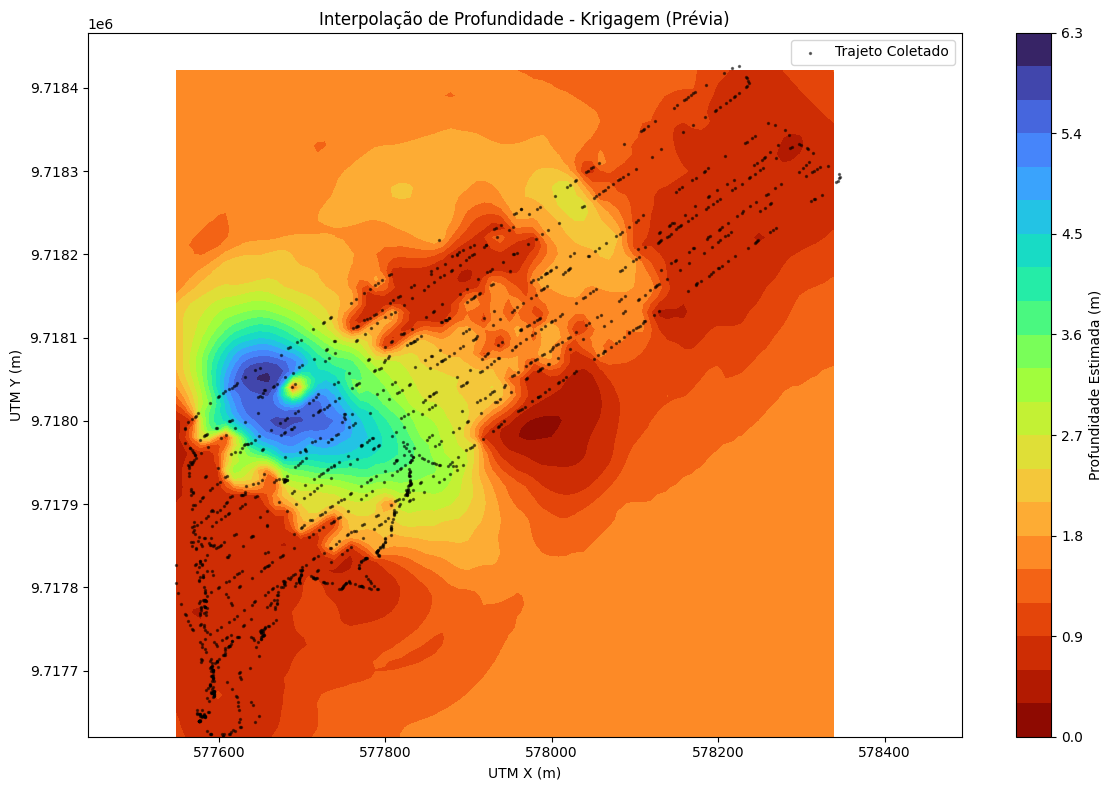

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from pykrige.ok import OrdinaryKriging
from pyproj import Transformer
import warnings
warnings.filterwarnings('ignore')

if not df.empty:
    # 1. Projetar as coordenadas de Lat/Lon (graus) para UTM (metros) 
    # EPSG:4326 (WGS84) para EPSG:32723 (UTM 23S) - Ajuste a zona UTM se necessário!
    transformer = Transformer.from_crs("EPSG:4326", "EPSG:32723", always_xy=True)
    
    df['utm_x'], df['utm_y'] = transformer.transform(df['lon'].values, df['lat'].values)
    
    # Reduzindo a amostra para a Krigagem não demorar muito nesta visualização inicial
    amostra_k = df if len(df) < 1500 else df.sample(1500)
    
    x = amostra_k['utm_x'].values
    y = amostra_k['utm_y'].values
    z = amostra_k['depth'].values
    
    # 2. Configurando e treinando a Krigagem Ordinária (Variograma Esférico)
    print("Configurando a Krigagem...")
    OK = OrdinaryKriging(
        x, y, z, 
        variogram_model='spherical',
        verbose=False,
        enable_plotting=False
    )
    
    # 3. Criando a grade (grid) onde vamos estimar as profundidades
    grid_space = 10 # Resolução de 10 metros
    grid_x = np.arange(np.min(x), np.max(x), grid_space)
    grid_y = np.arange(np.min(y), np.max(y), grid_space)
    
    # 4. Executando a interpolação (Z_pred)
    print(f"Executando Krigagem em uma grade de {len(grid_x)} x {len(grid_y)}...")
    z_pred, ss = OK.execute('grid', grid_x, grid_y)
    
    # 5. Plotando o resultado em um gráfico 2D (Matplotlib)
    plt.figure(figsize=(12, 8))
    
    # O cmap 'jet_r' (reverso) ou 'Blues' é ótimo para água (mais azul = mais fundo)
    contour = plt.contourf(grid_x, grid_y, z_pred, cmap='turbo_r', levels=20)
    plt.colorbar(contour, label='Profundidade Estimada (m)')
    
    # Plotar os pontos reais em cima do mapa
    plt.scatter(x, y, c='black', s=2, alpha=0.5, label='Trajeto Coletado')
    
    plt.title('Interpolação de Profundidade - Krigagem (Prévia)')
    plt.xlabel('UTM X (m)')
    plt.ylabel('UTM Y (m)')
    plt.legend()
    plt.axis('equal') # Mantém a proporção real sem achatar o mapa
    plt.tight_layout()
    plt.show()
else:
    print("Sem dados para rodar a Krigagem.")

## Definindo Limites Geográficos (Máscara de Contorno)

Quando fazemos a Krigagem em uma grade retangular, ela tenta prever profundidade até mesmo fora d'água (extrapolando para a terra seca). Para resolver isso, você pode desenhar um polígono que delimita exatamente a margem da água.

1. Rode a célula abaixo. Um mapa aparecerá.
2. Use a ferramenta do menu esquerdo (Polígono) para desenhar o contorno da área do rio.
3. Clique em **Export** (ou desenhe e salve) para baixar o arquivo `poligono.geojson`.
4. Mova esse arquivo `poligono.geojson` da sua pasta de Downloads para a pasta `batimetria rio bacanga/` aqui no projeto.

In [7]:
from folium.plugins import Draw
# Criando mapa base com imagem de satélite
centro = [df['lat'].mean(), df['lon'].mean()]
m_draw = folium.Map(location=centro, zoom_start=15, tiles=None)
# Substituindo pelo mapa Stadia Satellite usando a sua chave de API
folium.TileLayer(tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}', attr='Google', name='Google Satellite', max_zoom=22).add_to(m_draw)
# Plota amostra dos pontos
amostra_draw = df if len(df) < 2000 else df.sample(2000)
for idx, row in amostra_draw.iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=1, color='blue', fill=True
    ).add_to(m_draw)
# Adiciona ferramenta de desenho
Draw(
    export=True,
    filename='poligono.geojson',
    draw_options={
        "polyline": False, "rectangle": False, "circle": False,
        "marker": False, "circlemarker": False,
        "polygon": {"allowIntersection": False, "shapeOptions": {"color": "#FF0000"}}
    },
    edit_options={"edit": False}
).add_to(m_draw)
print("ATENÇÃO: Após desenhar, clique no botão 'Export' que aparecerá no mapa para salvar o GeoJSON!")
m_draw

ATENÇÃO: Após desenhar, clique no botão 'Export' que aparecerá no mapa para salvar o GeoJSON!


## Aplicando o Polígono e Recortando a Krigagem

Após ter movido o `poligono.geojson` para a pasta atual, vamos usá-lo para "mascarar" (recortar) o mapa de calor da Krigagem. Os pontos do mapa que caírem fora do polígono serão ocultados.

Arquivo Poligono Estudo_01.geojson encontrado! Recortando a grade...


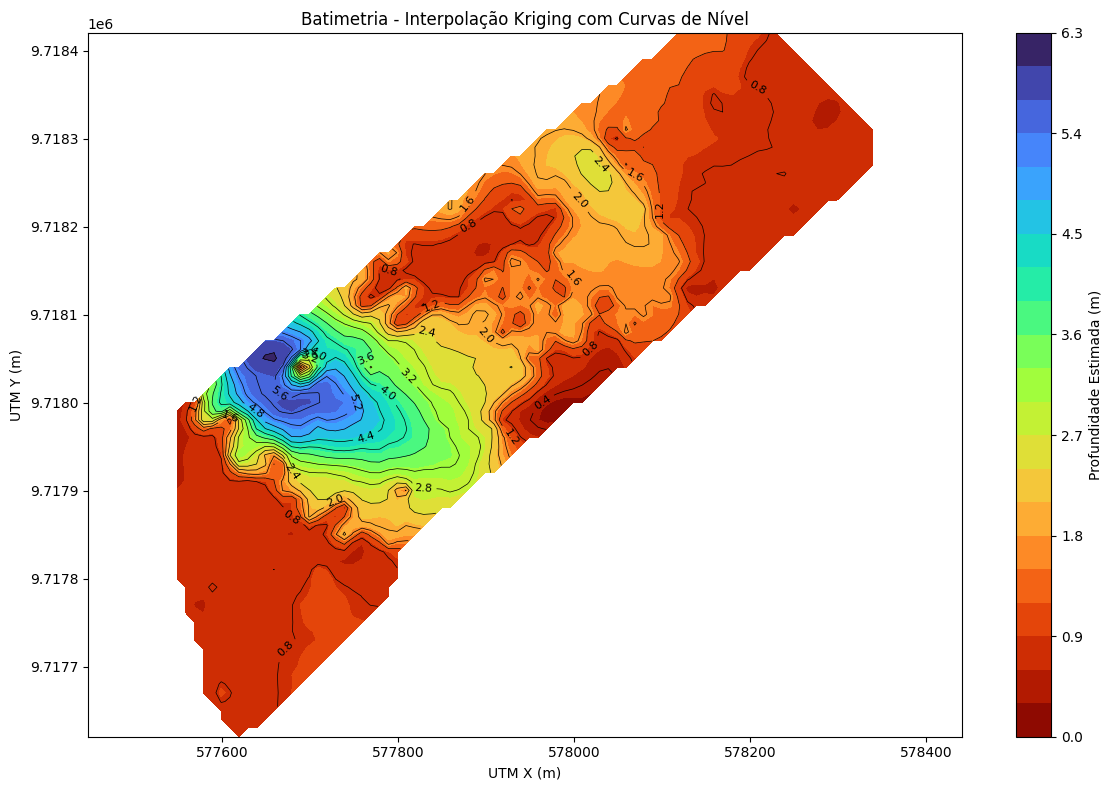

In [15]:
import geopandas as gpd
from shapely.geometry import Point
import os

if os.path.exists('Poligono Estudo_01.geojson'):
    print("Arquivo Poligono Estudo_01.geojson encontrado! Recortando a grade...")
    
    # 1. Lê o polígono WGS84 e converte para UTM (a mesma zona da Krigagem, 23S)
    gdf = gpd.read_file('Poligono Estudo_01.geojson')
    # Definindo EPSG de origem e destino
    gdf.set_crs(epsg=4326, inplace=True)
    gdf_utm = gdf.to_crs(epsg=32723)
    
    poly_utm = gdf_utm.geometry.iloc[0]
    
    # 2. Cria máscara verificando quais pontos da grade estão dentro do polígono
    X_grid, Y_grid = np.meshgrid(grid_x, grid_y)
    mask = np.zeros_like(X_grid, dtype=bool)
    
    # Isso pode ser um pouco lento dependendo da resolução da grade, aguarde...
    for i in range(X_grid.shape[0]):
        for j in range(X_grid.shape[1]):
            # Se o ponto não estiver dentro do polígono, mascara como True (ocultar)
            if not poly_utm.contains(Point(X_grid[i, j], Y_grid[i, j])):
                mask[i, j] = True
                
    # 3. Aplica a máscara no Z interpolado (Krigagem)
    z_pred_masked = np.ma.masked_array(z_pred, mask)
    
    # 4. Plota o resultado recortado
    plt.figure(figsize=(12, 8))
    
    # Mapa de calor (preenchimento)
    contourf = plt.contourf(grid_x, grid_y, z_pred_masked, cmap='turbo_r', levels=20)
    plt.colorbar(contourf, label='Profundidade Estimada (m)')
    
    # Adicionando curvas de nível (linhas)
    contour_lines = plt.contour(grid_x, grid_y, z_pred_masked, colors='black', linewidths=0.5, levels=15)
    plt.clabel(contour_lines, inline=True, fontsize=8, fmt='%1.1f')
    
    plt.title('Batimetria - Interpolação Kriging com Curvas de Nível')
    plt.xlabel('UTM X (m)')
    plt.ylabel('UTM Y (m)')
    plt.axis('equal') # Mantém a escala real
    plt.tight_layout()
    plt.show()
else:
    print("O arquivo 'poligono.geojson' não foi encontrado na pasta 'batimetria rio bacanga'.")
    print("Desenhe no mapa acima, faça o download e coloque na pasta para rodar esta célula!")

## Mapa Final de Batimetria com Satélite

Agora vamos gerar o plot estático final. Vamos sobrepor a nossa Krigagem com as curvas de nível **diretamente em cima de um mapa de satélite de alta resolução**, usando a biblioteca `contextily`. 

O parâmetro `set_aspect('equal')` garante que não haverá absolutamente **nenhuma distorção** (a escala ficará 1:1) e o mapa de fundo dará o contexto geográfico exato.

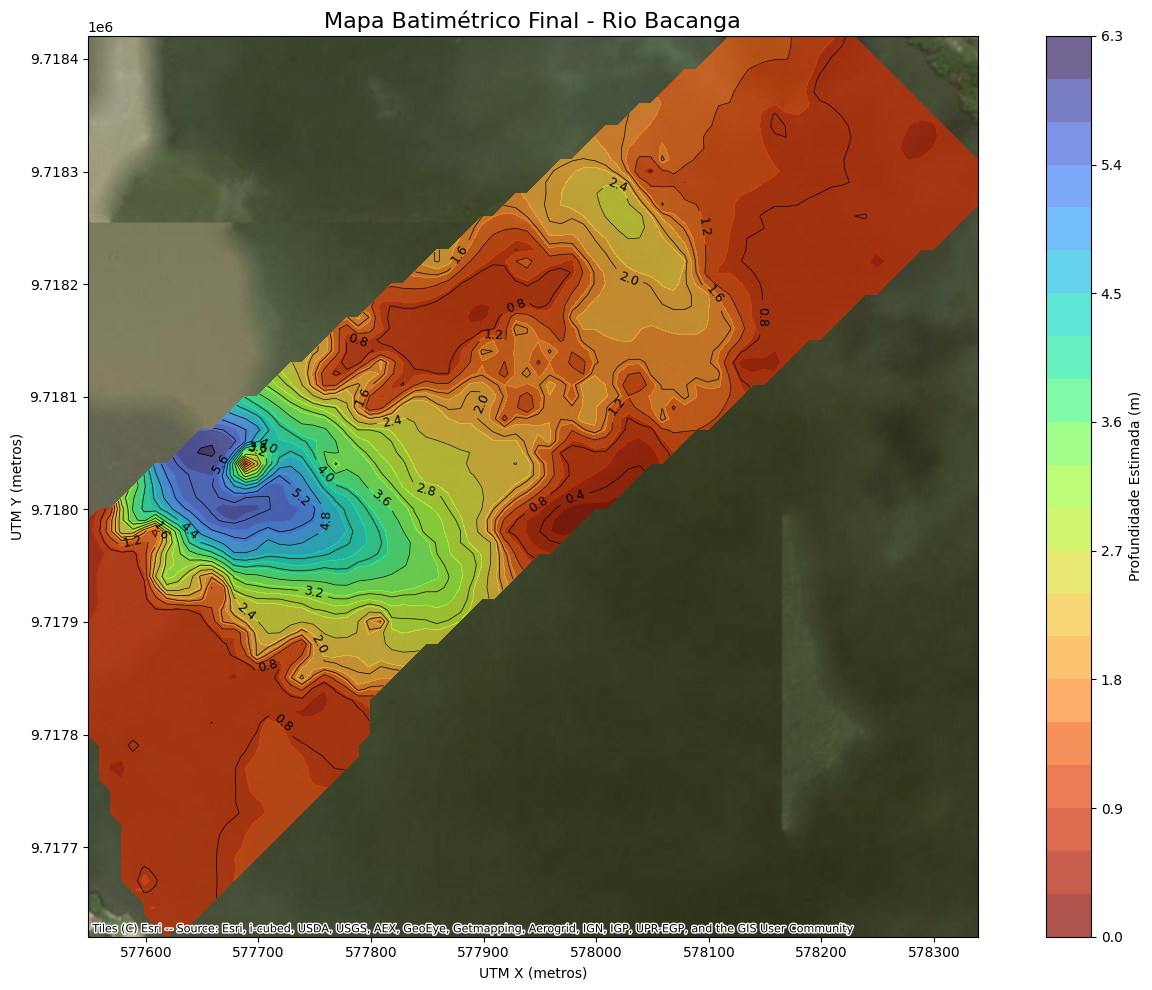

Sucesso! Mapa salvo em alta resolução na sua pasta como 'mapa_batimetria_satelite.png'


In [16]:
import contextily as ctx

fig, ax = plt.subplots(figsize=(14, 10))

# 1. Plotando a Krigagem recortada (com transparência alpha=0.7 para ver o fundo)
contourf = ax.contourf(grid_x, grid_y, z_pred_masked, cmap='turbo_r', levels=20, alpha=0.7)
plt.colorbar(contourf, ax=ax, label='Profundidade Estimada (m)')

# 2. Adicionando curvas de nível
contour_lines = ax.contour(grid_x, grid_y, z_pred_masked, colors='black', linewidths=0.5, levels=15)
ax.clabel(contour_lines, inline=True, fontsize=9, fmt='%1.1f')

# 3. Adicionando o mapa de satélite de fundo
# Informamos ao contextily que nossas coordenadas (grid_x, grid_y) estão em UTM 23S (EPSG:32723)
ctx.add_basemap(ax, crs='EPSG:32723', source=ctx.providers.Esri.WorldImagery)

ax.set_title('Mapa Batimétrico Final - Rio Bacanga', fontsize=16)
ax.set_xlabel('UTM X (metros)')
ax.set_ylabel('UTM Y (metros)')

# GARANTE A ESCALA REAL SEM NENHUMA DISTORÇÃO
ax.set_aspect('equal')

plt.tight_layout()
plt.savefig('mapa_batimetria_satelite.png', dpi=300, bbox_inches='tight')
plt.show()
print("Sucesso! Mapa salvo em alta resolução na sua pasta como 'mapa_batimetria_satelite.png'")

## Mapa Interativo em HTML (Folium)

Por fim, vamos gerar um mapa interativo completo (`.html`). Ele terá o mapa de calor com 60% de transparência, o mapa de satélite por baixo, e as curvas de nível por cima.
Você pode dar zoom, mover a tela, e se **passar o mouse por cima das linhas pretas**, ele mostrará a profundidade exata daquela curva!

Mapa salvo com sucesso! Abra 'mapa_interativo_final.html' no navegador.



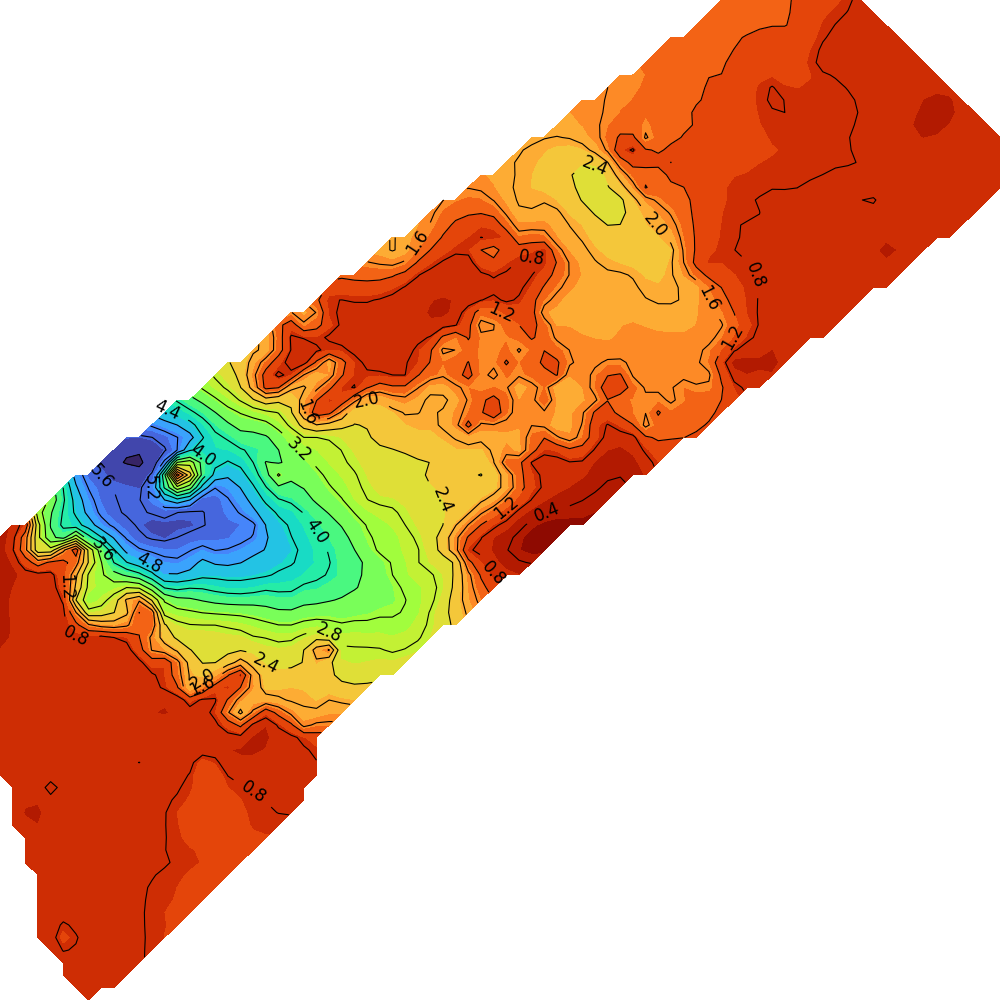

In [25]:
import folium
from folium import raster_layers
import base64
from io import BytesIO
from pyproj import Transformer
# 1. Configurando os limites da imagem
# Precisamos converter os extremos do nosso grid de UTM de volta para WGS84 (Lat/Lon)
trans_to_wgs = Transformer.from_crs("EPSG:32723", "EPSG:4326", always_xy=True)
lon_min, lat_min = trans_to_wgs.transform(np.min(grid_x), np.min(grid_y))
lon_max, lat_max = trans_to_wgs.transform(np.max(grid_x), np.max(grid_y))
bounds = [[lat_min, lon_min], [lat_max, lon_max]]
centro = [(lat_min + lat_max) / 2, (lon_min + lon_max) / 2]
# 2. Gerar a imagem do Mapa de Calor sem bordas
fig, ax = plt.subplots(figsize=(10, 10))
ax.axis('off')
ax.set_xlim(np.min(grid_x), np.max(grid_x))
ax.set_ylim(np.min(grid_y), np.max(grid_y))
# Plota a krigagem
ax.contourf(grid_x, grid_y, z_pred_masked, cmap='turbo_r', levels=20)

# Desenhando as linhas e os valores das curvas de nível diretamente na imagem PNG
contour_lines_img = ax.contour(grid_x, grid_y, z_pred_masked, colors='black', linewidths=0.8, levels=15)
ax.clabel(contour_lines_img, inline=True, fontsize=12, fmt='%1.1f')
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
fig.patch.set_alpha(0)
ax.patch.set_alpha(0)
# Salva a imagem em memória
buf = BytesIO()
plt.savefig(buf, format='png', transparent=True, pad_inches=0)
plt.close(fig)
# Convertendo a imagem PNG gerada em bytes para formato Data URL Base64 para o Folium
img_b64 = base64.b64encode(buf.getvalue()).decode('utf-8')
img_url = f'data:image/png;base64,{img_b64}'
# 3. Gerar os caminhos das Curvas de Nível
fig_lines, ax_lines = plt.subplots()
CS = ax_lines.contour(grid_x, grid_y, z_pred_masked, levels=15)
plt.close(fig_lines)
# 4. Criando o mapa interativo
m_html = folium.Map(location=centro, zoom_start=15, tiles=None)
# Mapa de satélite Stadia
folium.TileLayer(tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}', attr='Google', name='Google Satellite', max_zoom=22).add_to(m_html)
# Adicionando a imagem do mapa de calor (com 60% de opacidade)
raster_layers.ImageOverlay(
    image=img_url,
    bounds=bounds,
    opacity=0.6,
    name='Mapa de Calor'
).add_to(m_html)
# Adicionando as linhas de contorno por cima da imagem
for level, collection in zip(CS.levels, CS.allsegs):
    for seg in collection:
        if len(seg) < 2: continue
        # Converter vértices das linhas de UTM para Lat/Lon
        lons, lats = trans_to_wgs.transform(seg[:, 0], seg[:, 1])
        latlons = list(zip(lats, lons))
        folium.PolyLine(
            latlons,
            color='black',
            weight=1.5,
            opacity=0, # Deixando invisível porque as linhas já estão na imagem, mas mantendo para o hover
            tooltip=f"{level:.1f} m"
        ).add_to(m_html)
import branca.colormap as cm_branca
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Extraindo as cores do matplotlib para criar a barra de legenda no Folium
cmap = cm.get_cmap('turbo_r')
hex_colors = [mcolors.to_hex(cmap(i)) for i in np.linspace(0, 1, 10)]
# Pegando o mínimo e máximo real da interpolação recortada
vmin = float(np.nanmin(z_pred_masked.compressed() if hasattr(z_pred_masked, 'compressed') else z_pred_masked))
vmax = float(np.nanmax(z_pred_masked.compressed() if hasattr(z_pred_masked, 'compressed') else z_pred_masked))

colormap = cm_branca.LinearColormap(
    colors=hex_colors,
    vmin=vmin,
    vmax=vmax,
    caption='Profundidade (m)'
)
colormap.add_to(m_html)

folium.LayerControl().add_to(m_html)
m_html.save('mapa_interativo_final.html')
print("Mapa salvo com sucesso! Abra 'mapa_interativo_final.html' no navegador.")
m_html